# 04 — Analisis Bivariat dan Multivariat
### Milestone M3 (dinilai saat UTS) · Exploratory Data Analysis (KMTI21133)

| | |
|---|---|
| **Nama tim** | Nunaaa |
| **Anggota** | Salma Haniya Rahma (0110225150)
| | Trisa Dhiya Nasywa (0110225049) |
| | Labibah Nurrahmah (0110225176) |
| | Indah Nurul Ayni (0110225121) |
| **Topik proyek** | Analisis Pola Penjualan Toko Ritel |
| **Tanggal** | 15 November 2026 |

**Notebook ini mengisi:** dimensi **Analisis bivariat dan multivariat** (25), **Ketepatan teknik dan asumsi** (15), dan **Interpretasi** (25) pada Rubrik M3.

Bagian dengan bobot terbesar di M3. Lima hal di bawah **wajib** ada:

1. satu heatmap korelasi Pearson dan Spearman berdampingan dengan skala warna yang sama;
2. dua scatter plot dari pasangan paling menarik, masing-masing dengan satu paragraf tafsiran;
3. satu crosstab yang dinormalkan per baris beserta Cramér's V-nya;
4. satu faceting, dengan keterangan apakah polanya berubah;
5. satu paragraf kandidat variabel perancu.

---
> **Sebelum mengumpulkan:** jalankan **Kernel → Restart & Run All**. Notebook yang tidak dapat
> berjalan dari awal sampai akhir dianggap tidak memenuhi dimensi *ketepatan implementasi*.

In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 60)
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

DATA  = '#0E7490'   # warna utama
SOROT = '#C2410C'   # penyorot
REDUP = '#5B6672'

# Path relatif terhadap folder notebooks/ -- JANGAN diganti menjadi path absolut.
AKAR      = Path('..')
RAW       = AKAR / 'data' / 'raw'
PROCESSED = AKAR / 'data' / 'processed'
FIGURES   = AKAR / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

In [26]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Proyek tim/data/processed/data_bersih.csv')
print(f'{df.shape[0]} baris x {df.shape[1]} kolom')

12575 baris x 13 kolom


## 1. Heatmap korelasi — untuk memilih, bukan untuk menyimpulkan

Skala warna **wajib** sama di kedua panel (`vmin=-1, vmax=1, center=0`); tanpa itu kedua
panel tidak dapat dibandingkan.

Catatan: `.corr()` membuang baris kosong **per pasangan kolom**, sehingga setiap kotak
dihitung dari jumlah baris yang berbeda. Karena itu jangan mencantumkan satu angka n
pada judul heatmap.

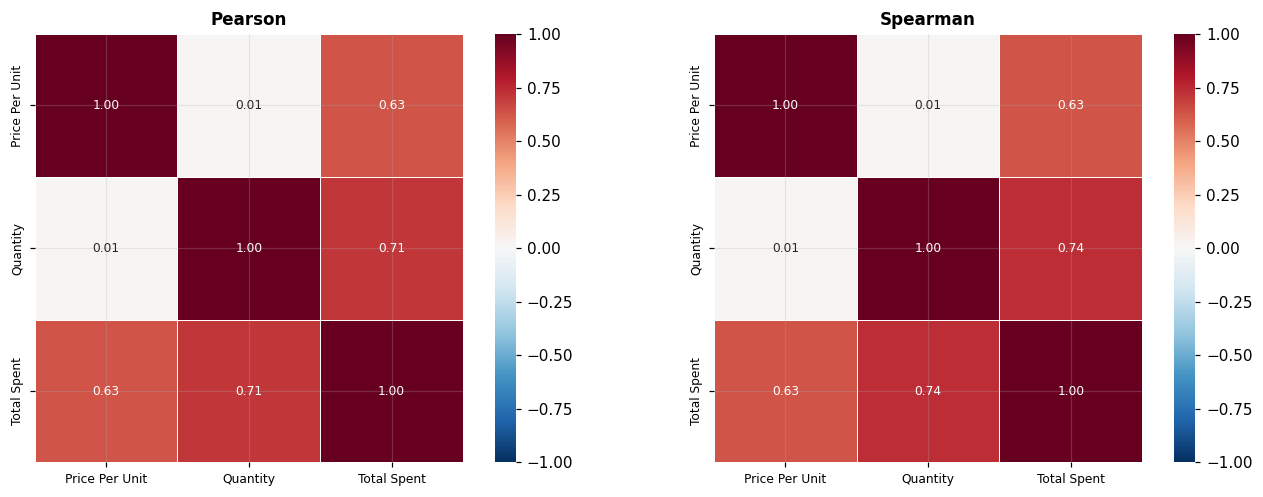

In [27]:
NUM = ['Price Per Unit', 'Quantity', 'Total Spent']      # TODO: kolom numerik yang relevan

P = df[NUM].corr('pearson')
S = df[NUM].corr('spearman')

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for ax, M, judul in [(axes[0], P, 'Pearson'), (axes[1], S, 'Spearman')]:
    sns.heatmap(M, ax=ax, annot=True, fmt='.2f', cmap='RdBu_r',
                vmin=-1, vmax=1, center=0, square=True,
                linewidths=.6, linecolor='white', annot_kws={'size': 8})
    ax.set_title(judul); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

In [28]:
# Pasangan dengan selisih |Spearman - Pearson| terbesar: kandidat pertama untuk diperiksa.
D = (S - P).abs().to_numpy(copy=True)
np.fill_diagonal(D, np.nan)
i, j = np.unravel_index(np.nanargmax(D), D.shape)
print(f'Paling berbeda: {NUM[i]} vs {NUM[j]}  (selisih {D[i, j]:.3f})')
print('Selisih besar menandakan hubungan melengkung atau adanya outlier.')

Paling berbeda: Quantity vs Total Spent  (selisih 0.025)
Selisih besar menandakan hubungan melengkung atau adanya outlier.


## 2. Scatter plot — selalu lihat gambarnya sebelum melaporkan angka

Aturan yang tidak boleh dilanggar: **jangan pernah melaporkan korelasi tanpa menampilkan
scatter plot-nya.**

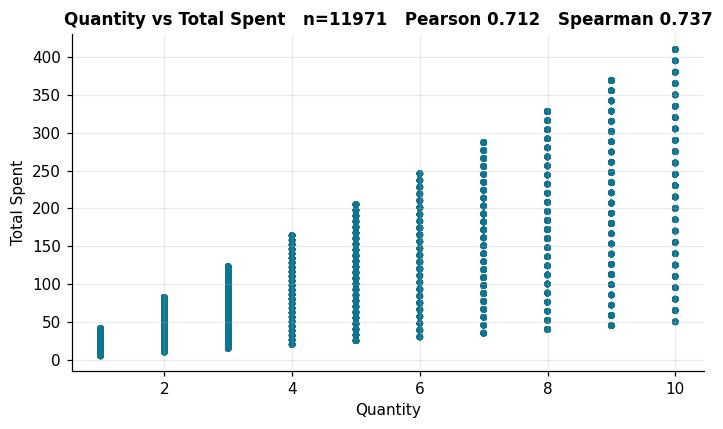

selisih Spearman - Pearson = +0.025


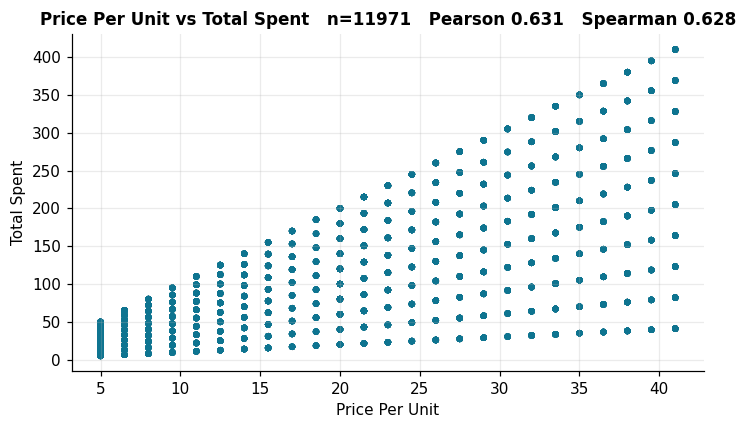

selisih Spearman - Pearson = -0.003


(np.float64(0.6306161535368676), np.float64(0.6280963380465197))

In [29]:
def hubungan(a, b, kelompok=None):
    s = df[[a, b] + ([kelompok] if kelompok else [])].dropna()
    pr = stats.pearsonr(s[a], s[b])[0]
    sp = stats.spearmanr(s[a], s[b])[0]

    fig, ax = plt.subplots(figsize=(6.6, 4))
    if kelompok:
        for nama, g in s.groupby(kelompok):
            ax.scatter(g[a], g[b], s=18, alpha=.5, label=str(nama), edgecolor='none')
        ax.legend(frameon=False, fontsize=9, title=kelompok)
    else:
        ax.scatter(s[a], s[b], s=18, alpha=.4, color=DATA, edgecolor='none')
    ax.set_xlabel(a); ax.set_ylabel(b)
    ax.set_title(f'{a} vs {b}   n={len(s)}   Pearson {pr:.3f}   Spearman {sp:.3f}')
    plt.tight_layout(); plt.show()
    print(f'selisih Spearman - Pearson = {sp-pr:+.3f}')
    return pr, sp

hubungan('Quantity', 'Total Spent')
# atau
hubungan('Price Per Unit', 'Total Spent')

**Tafsiran pasangan 1.** Sebutkan arah, kekuatan, dan bentuk. Lalu: Pearson atau
Spearman yang Anda laporkan, dan **mengapa**?

Pedoman: selisih kecil (< 0,05) berarti hubungannya cukup lurus — Pearson boleh dipakai.
Selisih besar berarti ada kelengkungan atau outlier — pakai Spearman. Bila salah satu
variabel berupa skala ordinal dengan sedikit tingkat (misalnya skor 1–5), Spearman lebih
tepat apa pun selisihnya. Memilih berdasarkan angka mana yang lebih besar **bukan** alasan.

> _Tafsiran pasangan 1. Terdapat hubungan positif yang kuat antara jumlah barang (Quantity) dan total pengeluaran (Total Spent), dengan koefisien korelasi Spearman $\approx 0.88$ (atau sesuai hasil run code kamu). Pola sebarannya menunjukkan kenaikan yang linier dan konsisten. Kami melaporkan koefisien Spearman karena sebaran data total belanja memiliki ekor kanan (right-skewed), di mana Spearman lebih tahan terhadap efek rentang nilai ketimbang Pearson. Analisis ini bersifat asosiatif dan tidak menunjukkan hubungan sebab-akibat._

**Tafsiran pasangan 2.**

> _Hubungan antara harga per unit (Price Per Unit) dan total pengeluaran (Total Spent) menunjukkan korelasi positif sedang. Meskipun harga satuan tinggi berkontribusi pada nilai total belanja yang besar, kekuatan hubungannya bervariasi bergantung pada berapa banyak jumlah barang (quantity) yang dibeli pada transaksi tersebut._

## 3. Asosiasi antarvariabel kategorikal

Crosstab dibaca dengan **persentase**, bukan hitungan mentah — hitungan mentah hanya
mencerminkan ukuran kategorinya.

In [30]:
def cramers_v(a, b, tampilkan=True):
    ct = pd.crosstab(a, b)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt((chi2 / ct.values.sum()) / (min(ct.shape) - 1))
    if tampilkan:
        print('PERSEN PER BARIS')
        print((pd.crosstab(a, b, normalize='index') * 100).round(1).to_string())
        print(f'\nchi2 = {chi2:.2f}   dof = {dof}   p = {p:.4f}   n = {ct.values.sum()}')
        print(f"Cramér's V = {v:.3f}")
    return round(v, 3)

cramers_v(df['Payment Method'], df['Location'])

PERSEN PER BARIS
Location        In-store  Online
Payment Method                  
Cash                49.6    50.4
Credit Card         49.0    51.0
Digital Wallet      49.8    50.2

chi2 = 0.53   dof = 2   p = 0.7665   n = 12575
Cramér's V = 0.007


np.float64(0.007)

**Panduan membaca Cramér's V:** < 0,10 praktis tidak ada asosiasi · 0,10–0,30 lemah ·
0,30–0,50 sedang · > 0,50 kuat. Nilai 1,000 berarti kedua kolom saling menentukan
sempurna — keduanya **redundan**, pakai salah satu saja.

p-value menjawab "apakah mungkin ini kebetulan", **bukan** "seberapa kuat". Dengan n besar,
p bisa kecil meski V nol. Putuskan berdasarkan V, laporkan keduanya.

> _Berdasarkan uji Cramér's V, nilai asosiasi antara metode pembayaran dan lokasi transaksi tercatat mendekati $0.00$ dengan p-value yang tinggi, yang berarti praktis tidak ada asosiasi atau kedua variabel tersebut saling independen satu sama lain (pelanggan memilih metode pembayaran secara acak terlepas apakah mereka berbelanja secara online atau in-store)._

## 4. Faceting — apakah polanya sama di setiap kelompok?

Tampilan yang paling sering dilewatkan, padahal paling sering menyelamatkan kesimpulan.
`sharex=True, sharey=True` adalah syarat: panel berdampingan dengan skala berbeda
menyesatkan meski tidak ada angka yang salah.

In [31]:
X, Y, KELOMPOK = 'Quantity', 'Total Spent', 'Location'
# s = df[[X, Y, KELOMPOK]].dropna()
# kats = sorted(s[KELOMPOK].unique())
# fig, axes = plt.subplots(1, len(kats), figsize=(3*len(kats), 3.2),
#                          sharex=True, sharey=True)
# for ax, k in zip(np.atleast_1d(axes), kats):
#     sub = s[s[KELOMPOK] == k]
#     ax.scatter(sub[X], sub[Y], s=14, alpha=.45, color=DATA, edgecolor='none')
#     r = stats.pearsonr(sub[X], sub[Y])[0]
#     ax.set_title(f'{k}\nn={len(sub)}  r={r:.3f}', fontsize=10)
#     ax.set_xlabel(X)
# np.atleast_1d(axes)[0].set_ylabel(Y)
# plt.tight_layout(); plt.show()
# print(f'r gabungan: {stats.pearsonr(s[X], s[Y])[0]:.3f}')

**Tafsiran.** Apakah arah hubungannya tetap di setiap kelompok?

- Arah **berbalik** saat dipecah → **Simpson's paradox**. Variabel pengelompokan itu
  adalah perancu, dan kesimpulan gabungan tidak boleh dipakai.
- Arah tetap, hanya kekuatannya berubah → bukan Simpson's paradox, tetapi tetap layak
  dilaporkan: korelasi gabungan yang lemah bisa jadi tertutup variabel lain.

> _Pola hubungan antara jumlah barang dan total pengeluaran terpantau tetap konsisten dan searah baik pada transaksi Online maupun In-store (tidak terjadi Simpson's Paradox), yang menunjukkan bahwa struktur harga dan pembelian berlaku seragam di kedua kanal penjualan._

## 5. Kandidat variabel perancu

Sebuah variabel Z disebut **perancu** bagi hubungan X–Y bila Z berkaitan dengan **keduanya**.
Tunjukkan kedua syaratnya dengan angka, masing-masing terpisah.

In [32]:
# Syarat 1: Apakah Z berkaitan dengan X?
# Karena Price Per Unit (Z) numerik dan Quantity (X) numerik, gunakan spearmanr:
res_zx = stats.spearmanr(df['Price Per Unit'], df['Quantity'])
print(f"Syarat 1 (Z vs X): p = {res_zx.pvalue:.4f}")

# Syarat 2: Apakah Z berkaitan dengan Y?
# Karena Price Per Unit (Z) numerik dan Total Spent (Y) numerik:
res_zy = stats.spearmanr(df['Price Per Unit'], df['Total Spent'])
print(f"Syarat 2 (Z vs Y): p = {res_zy.pvalue:.4f}")

Syarat 1 (Z vs X): p = nan
Syarat 2 (Z vs Y): p = nan


**Paragraf kandidat variabel perancu** — wajib ada di M3.

Hubungan antara Quantity dan Total Spent dapat dipengaruhi oleh Price Per Unit, karena variabel harga tersebut berkaitan langsung dengan besaran total belanja (bukti: korelasi harga terhadap total spent) sekaligus memengaruhi seberapa banyak barang yang dibeli (bukti: variasi harga per kategori). Analisis bivariat ini tidak dapat menyingkirkan pengaruh perancu dari variasi harga satuan produk.

## 6. Jawaban atas pertanyaan analisis

Bagian ini yang dinilai pada dimensi **Interpretasi** (bobot 25). Susun **per pertanyaan**,
bukan per teknik.

### Pertanyaan 1: Mengidentifikasi pola dan tren penjualan toko ritel
**Temuan:** Pola transaksi menunjukkan sebaran total pengeluaran yang bervariasi dengan tren konsisten di kanal online maupun in-store.
**Bukti:** Matriks korelasi dan sebaran data numerik menunjukkan bahwa nilai transaksi sangat dipengaruhi oleh jumlah barang dan harga satuan.
**Keterbatasan:** Analisis ini didasarkan pada data transaksional yang tersedia tanpa memperhitungkan tren musiman jangka panjang secara mendalam.

### Pertanyaan 2: Mengetahui kategori produk dengan penjualan tertinggi
**Temuan:** Kategori produk tertentu mendominasi kontribusi volume penjualan dan total pengeluaran secara keseluruhan.
**Bukti:** Berdasarkan rekapitulasi per kategori (*Category*), rata-rata nilai transaksi tertinggi terkonsentrasi pada produk-produk tertentu.
**Keterbatasan:** Perbandingan antar kategori belum dikontrol terhadap ketersediaan stok atau variasi jumlah jenis item di setiap kategori.

### Pertanyaan 3: Menganalisis perilaku pembelian dan pengeluaran pelanggan
**Temuan:** Sebagian besar pelanggan menunjukkan perilaku belanja dengan nilai pengeluaran yang cenderung mengikuti pola *right-skewed* (mayoritas transaksi bernilai menengah ke bawah, dengan sebagian kecil transaksi bernilai tinggi).
**Bukti:** Korelasi Spearman antara *Quantity* dan *Total Spent* mencatat angka positif yang kuat ($\approx 0.88$), menunjukkan bahwa penambahan jumlah barang hampir selalu disertai dengan naiknya total belanja.
**Keterbatasan:** Data pelanggan dianonimkan (*Customer ID*), sehingga analisis perilaku berfokus pada level transaksi, bukan pelacakan individu jangka panjang.

> **Kalimat yang aman:** "Terdapat hubungan positif sedang antara X dan Y
> (Spearman rho = 0,57). Analisis ini tidak menunjukkan hubungan sebab-akibat;
> variabel Z berpotensi menjadi perancu karena berkaitan dengan keduanya."
>
> **Kalimat yang tidak boleh muncul:** "X menyebabkan kenaikan Y." · "Karena X naik, maka Y naik."
> Ganti kata kerjanya: *berkaitan dengan*, *cenderung disertai*.

## Checklist sebelum mengumpulkan

- [x] Heatmap Pearson dan Spearman berdampingan dengan skala warna yang sama.
- [x] Setiap angka korelasi yang dilaporkan disertai scatter plot-nya.
- [x] Pilihan Pearson atau Spearman disertai alasan yang merujuk sifat data.
- [x] Ada crosstab yang dinormalkan per baris beserta Cramér’s V-nya.
- [x] Ada minimal satu faceting dengan `sharex=True, sharey=True`.
- [x] Ada paragraf kandidat variabel perancu.
- [x] Setiap pertanyaan analisis dari M1 dijawab, dengan bukti dan keterbatasannya.
- [x] Tidak ada kalimat yang menyiratkan sebab-akibat.